## This is the LLM benchmark

In [ ]:
from pathlib import Path
import pandas as pd

path = Path("Financial Phrasebank Project/data/splits")

train_df = pd.read_csv(path / "train.csv")
validation_df = pd.read_csv(path / "validation.csv")
test_df = pd.read_csv(path / "test.csv")

print("Train:", train_df.shape)
print("Validation:", validation_df.shape)
print("Test:", test_df.shape)

Train: (2947, 3)
Validation: (632, 3)
Test: (632, 3)


## Labels
To map what the model predicted with the actual class we need to reverse the lables
ex: model returns : negative / neutral / positive
later we can do: LABEL2ID["positive"] which returns 2

In [ ]:
LABELS = {
    0: "negative",
    1: "neutral",
    2: "positive"
}

LABEL2ID = {
    "negative": 0,
    "neutral": 1,
    "positive": 2
}

### First create a very small stratified pilot sample because our validation set is imbalanced
the code below should give us:

3 negative
3 neutral
3 positive

= 9 sentences total

It is a debugging experiement to test if the LLM understands the task and can output one of the three labels reliably

In [ ]:
pilot_df = (
    validation_df
    .groupby("label", group_keys=False)
    .sample(n=3, random_state=42)
    .reset_index(drop=True)
)

pilot_df[["sentence", "label"]]

,sentence,label
0,"UPM-Kymmene Corp. , the world 's largest maker...",0
1,They are also upset that some of the machinery...,0
2,`` Uncommonly weak snow conditions in nearly e...,0
3,Russia 's Video International Group holds a co...,1
4,The report contains category level company and...,1
5,Equipment will be manufactured in Vaahto 's wo...,1
6,Cargotec Germany GmbH has been awarded a contr...,2
7,The representative body of Swedish Meats appro...,2
8,It therefore seems that Finnish shipping compa...,2


### Convert the Labels so they are easier to read
Now instead of seeing:

sentence:                               

label

Company profit decreased...               

0

we will see:

sentence                               

true_sentiment

Company profit decreased...            

negative

In [ ]:
pilot_df["true_sentiment"] = pilot_df["label"].map(LABELS)

pd.set_option("display.max_colwidth", None)

pilot_df[["sentence", "true_sentiment"]]

,sentence,true_sentiment
0,"UPM-Kymmene Corp. , the world 's largest maker of magazine paper , on Tuesday reported a 19-percent profit drop as lower paper prices , higher costs and a strong euro hurt revenue .",negative
1,They are also upset that some of the machinery and work is taken over to Poland .,negative
2,"`` Uncommonly weak snow conditions in nearly every market have affected our first quarter result , '' Chief Executive Roger Talermo said .",negative
3,Russia 's Video International Group holds a controlling stake in Russian Media Ventures .,neutral
4,The report contains category level company and brand share as well as distribution share information for 2007 and 2008 .,neutral
5,"Equipment will be manufactured in Vaahto 's workshop in Hollola , Finland and is scheduled for shipments during the first quarter of 2009 .",neutral
6,Cargotec Germany GmbH has been awarded a contract by Stadtverwaltung Mainz for chassis bodies under Open procedure .,positive
7,The representative body of Swedish Meats approved an improved offer from Finnish HK Ruokatalo to acquire the company .,positive
8,It therefore seems that Finnish shipping company Viking Line will get the subsidy it needs to order its new LNG-fuelled vessel .,positive


## Design the LLM Prompt
We will start with a zero-shot prompt

In [ ]:
def build_prompt(sentence):
    return f"""
You are performing financial sentiment classification.

Classify the following financial news sentence from the perspective
of an investor.

Use exactly one of these labels:

negative = the information has financially unfavorable implications
neutral = the information has no clear positive or negative financial implication
positive = the information has financially favorable implications

Return only the label: negative, neutral, or positive.

Sentence:
{sentence}
""".strip()

In [ ]:
print(build_prompt(pilot_df.loc[0, "sentence"]))

You are performing financial sentiment classification.

Classify the following financial news sentence from the perspective
of an investor.

Use exactly one of these labels:

negative = the information has financially unfavorable implications
neutral = the information has no clear positive or negative financial implication
positive = the information has financially favorable implications

Return only the label: negative, neutral, or positive.

Sentence:
UPM-Kymmene Corp. , the world 's largest maker of magazine paper , on Tuesday reported a 19-percent profit drop as lower paper prices , higher costs and a strong euro hurt revenue .


## Call LLM

In [ ]:
import os

print("Gemini key available:", bool(os.getenv("GEMINI_API_KEY")))

Gemini key available: True


In [ ]:
!pip install -q -U google-genai


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [ ]:
from google import genai

client = genai.Client()
MODEL_NAME = "gemini-3.5-flash-lite"

In [ ]:
response = client.models.generate_content(
    model=MODEL_NAME,
    contents=build_prompt(pilot_df.loc[0, "sentence"])
)

print(response.text)

negative


In [ ]:
#make a reusable classification function
import time

VALID_LABELS = {"negative", "neutral", "positive"}

def classify_with_gemini(sentence):
    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=build_prompt(sentence)
    )

    prediction = response.text.strip().lower()

    if prediction not in VALID_LABELS:
        raise ValueError(
            f"Unexpected Gemini output: {prediction}"
        )

    return prediction

In [ ]:

#next we run all 9 pilot sentences sequentially because we dont want to overwhelm the API with parallel requests
predictions = []

for i, sentence in enumerate(pilot_df["sentence"]):
    print(f"Classifying {i + 1}/{len(pilot_df)}...")

    prediction = classify_with_gemini(sentence)
    predictions.append(prediction)

    time.sleep(1)

Classifying 1/9...
Classifying 2/9...
Classifying 3/9...
Classifying 4/9...
Classifying 5/9...
Classifying 6/9...
Classifying 7/9...
Classifying 8/9...
Classifying 9/9...


In [ ]:
#create a column of predictions
pilot_df["llm_prediction"] = predictions

In [ ]:
#make a comparison with actual label and what was return by model
pilot_df["correct"] = (
    pilot_df["true_sentiment"]
    == pilot_df["llm_prediction"]
)

pilot_df[
    [
        "sentence",
        "true_sentiment",
        "llm_prediction",
        "correct"
    ]
]

,sentence,true_sentiment,llm_prediction,correct
0,"UPM-Kymmene Corp. , the world 's largest maker of magazine paper , on Tuesday reported a 19-percent profit drop as lower paper prices , higher costs and a strong euro hurt revenue .",negative,negative,True
1,They are also upset that some of the machinery and work is taken over to Poland .,negative,negative,True
2,"`` Uncommonly weak snow conditions in nearly every market have affected our first quarter result , '' Chief Executive Roger Talermo said .",negative,negative,True
3,Russia 's Video International Group holds a controlling stake in Russian Media Ventures .,neutral,neutral,True
4,The report contains category level company and brand share as well as distribution share information for 2007 and 2008 .,neutral,neutral,True
5,"Equipment will be manufactured in Vaahto 's workshop in Hollola , Finland and is scheduled for shipments during the first quarter of 2009 .",neutral,positive,False
6,Cargotec Germany GmbH has been awarded a contract by Stadtverwaltung Mainz for chassis bodies under Open procedure .,positive,positive,True
7,The representative body of Swedish Meats approved an improved offer from Finnish HK Ruokatalo to acquire the company .,positive,positive,True
8,It therefore seems that Finnish shipping company Viking Line will get the subsidy it needs to order its new LNG-fuelled vessel .,positive,positive,True


In [ ]:
#calculate a score for the pilot
pilot_accuracy = pilot_df["correct"].mean()

print("Pilot accuracy:", pilot_accuracy)

Pilot accuracy: 0.8888888888888888


## Do the classification with a higher sample size
Now we move to a larger stratified validation sample, around 100 sentences. This gives us enough examples to calculate meaningful Macro-F1 and class-specific performance before deciding whether zero-shot is good enough.

In [ ]:
from sklearn.model_selection import train_test_split

validation_sample, _ = train_test_split(
    validation_df,
    train_size=100,
    random_state=42,
    stratify=validation_df["label"]
)

validation_sample = validation_sample.reset_index(drop=True)

validation_sample["true_sentiment"] = (
    validation_sample["label"].map(LABELS)
)

print(validation_sample["true_sentiment"].value_counts())

true_sentiment
neutral     60
positive    28
negative    12
Name: count, dtype: int64


In [ ]:
import time
import pandas as pd
from pathlib import Path

progress_path = Path("zero_shot_progress.csv")

# Resume previous work if it exists
if progress_path.exists():
    progress_df = pd.read_csv(progress_path)
    predictions = progress_df["prediction"].tolist()
    print(f"Resuming from {len(predictions)} saved predictions.")
else:
    predictions = []
    print("Starting a new zero-shot run.")

start_index = len(predictions)

for i in range(start_index, len(validation_sample)):
    sentence = validation_sample.loc[i, "sentence"]

    print(f"Classifying {i + 1}/{len(validation_sample)}...")

    success = False

    for attempt in range(5):
        try:
            prediction = classify_with_gemini(sentence)

            predictions.append(prediction)
            success = True
            break

        except Exception as e:
            error_message = str(e)

            print(f"Attempt {attempt + 1} failed.")

            # Rate limit / quota problem
            if "429" in error_message or "RESOURCE_EXHAUSTED" in error_message:
                wait_time = 30 * (attempt + 1)
                print(f"Rate limit hit. Waiting {wait_time} seconds...")
                time.sleep(wait_time)

            # Temporary Gemini server problem
            elif "503" in error_message or "UNAVAILABLE" in error_message:
                wait_time = 2 ** attempt
                print(f"Server busy. Retrying in {wait_time} seconds...")
                time.sleep(wait_time)

            else:
                print(error_message)
                break

    # If all retries fail, STOP instead of inserting a fake/missing prediction
    if not success:
        print(
            f"Stopping safely at sentence {i + 1}. "
            "All previous predictions have been preserved."
        )
        break

    # Save after EVERY successful classification
    pd.DataFrame({
        "prediction": predictions
    }).to_csv(progress_path, index=False)

    # Slow request rate
    time.sleep(3)

Resuming from 100 saved predictions.


In [ ]:
validation_sample["llm_prediction"] = predictions

validation_sample["correct"] = (
    validation_sample["true_sentiment"]
    == validation_sample["llm_prediction"]
)

In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_true = validation_sample["true_sentiment"]
y_pred = validation_sample["llm_prediction"]

print(
    "Accuracy:",
    accuracy_score(y_true, y_pred)
)

print(
    "Macro-F1:",
    f1_score(
        y_true,
        y_pred,
        average="macro"
    )
)

print(
    classification_report(
        y_true,
        y_pred,
        labels=["negative", "neutral", "positive"]
    )
)

Accuracy: 0.85
Macro-F1: 0.8545914033299354
              precision    recall  f1-score   support

    negative       0.80      1.00      0.89        12
     neutral       0.96      0.78      0.86        60
    positive       0.72      0.93      0.81        28

    accuracy                           0.85       100
   macro avg       0.83      0.90      0.85       100
weighted avg       0.87      0.85      0.85       100



[[12  0  0]
 [ 3 47 10]
 [ 0  2 26]]


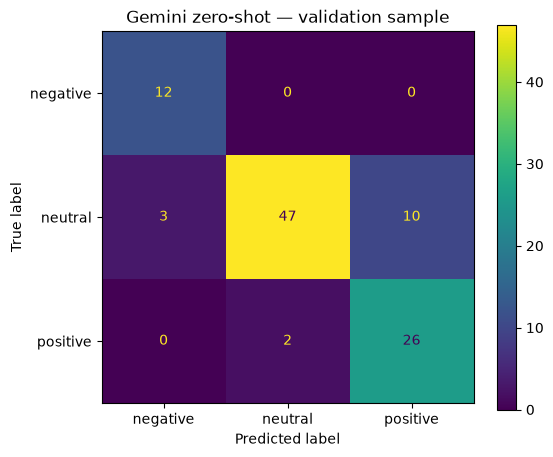

In [ ]:
#build confusion matrix
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["negative", "neutral", "positive"]

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=labels
)

print(cm)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=labels
).plot(ax=ax)

ax.set_title("Gemini zero-shot — validation sample")

plt.show()

In [ ]:
#inspect the errors
#since we have accuracy of 86% that means that: 100 examples - 86 correct = 14 errors so 14 sentences to inspect
gemini_errors = validation_sample[
    validation_sample["true_sentiment"]
    != validation_sample["llm_prediction"]
].copy()

print("Number of errors:", len(gemini_errors))

gemini_errors[
    [
        "sentence",
        "true_sentiment",
        "llm_prediction"
    ]
]

Number of errors: 15


,sentence,true_sentiment,llm_prediction
7,"Tikkurila has an interesting growth strategy , which we support .",neutral,positive
18,About Elcoteq Elcoteq SE is a leading electronics manufacturing services ( EMS ) company in the communications technology field .,positive,neutral
31,"The Vuokatti unit will be developed to focus especially on the manufacture of prototypes , the ramp-up of new products and the demanding testing and after-sales services .",neutral,positive
39,"Pearl Plaza LLC , the joint venture of SRV and Shanghai Industrial Investment Holdings Co Ltd , has concluded the investment decision on construction of the first phase of the shopping center in Saint Petersburg , Russia .",positive,neutral
43,"Thanks to its extensive industry and operations experience , Cybercom offers strategic and technological expertise to these markets : telecom , industry , media , public sector , retail , and banking and financial services .",neutral,positive
50,Sunrise Resources operates in Russian near-shore development markets through its wholly-owned Russian subsidiary and has 80 % of its personnel in Russia .,neutral,negative
51,"The orders are for 26 machine-room-less KONE MonoSpace elevators , which would be installed during 2006 .",neutral,positive
63,"The company will pay a dividend of EUR 0.50 per share , a total of EUR 14mn .",neutral,positive
74,"Equipment will be manufactured in Vaahto 's workshop in Hollola , Finland and is scheduled for shipments during the first quarter of 2009 .",neutral,positive
80,"`` Soon after , the collisions started . ''",neutral,negative


## Few-Shot attempt

In [ ]:
#because the zero-shot model is struggling to capture neutral examples and it is labelling them as positive
# we can try using few-shot to see if this improves

#inspect some of the training candidates
for label_id, label_name in LABELS.items():
    print(f"\n--- {label_name.upper()} ---")

    examples = (
        train_df[train_df["label"] == label_id]
        .sample(n=10, random_state=42)
    )

    for sentence in examples["sentence"]:
        print("-", sentence)


--- NEGATIVE ---
- Operating profit decreased to EUR 16mn from EUR 21.1 mn in 2008 .
- Finnish plumbing and heating systems supplier Uponor 's net sales in continuing business operations decreased to EUR 249.1 mn in July-September 2008 , compared to EUR 262.1 mn in the third quarter of 2007 .
- The maritime administration said the ships had ignored warnings about the icy conditions .
- Dealers said the share was largely hit by investor disappointment about a refining margin of just 9.48 usd per barrel for the quarter and the performance of its shipping unit , which saw EBIT drop to 5 mln eur from 20 mln eur a year amid a fall in volumes and tanker rates .
- Finnish media company Talentum Oyj 's net profit decreased to 2.5 mln euro ( $ 4.0 mln ) for the first quarter of 2008 from 3.0 mln euro ( $ 4.7 mln ) for the same period of 2007 .
- Nokia 's share price fell less than one percent to 18.70 euros ( $ 25.41 ) in Helsinki , while Siemens shares fell 1.02 percent to 90.19 euros ( $ 122

In [ ]:
few_shot_examples = [
    ("The maritime administration said the ships had ignored warnings about the icy conditions .", "negative"),
    ("Dealers said the share was largely hit by investor disappointment about a refining margin of just 9.48 usd per barrel for the quarter and the performance of its shipping unit , which saw EBIT drop to 5 mln eur from 20 mln eur a year amid a fall in volumes and tanker rates .", "negative"),
    ("The sale of the food potato business is part of Raisio 's plan to streamline and clarify its business operations .", "neutral"),
    ("The transaction covers a building lot of 46,763 sq m and factory buildings of 19,631 sq m. Since the autumn of 2007 , when Scanfil discontinued its production operations in Oulu , the facilities have been partly leased to other parties .", "neutral"),
    ("The Finnish group anticipates a sales gain of EUR42m after tax and expenses .", "positive"),
    ("ADPnews - Jun 30 , 2009 - Finnish stainless steel maker Outokumpu Oyj HEL : OUT1V said yesterday it signed a three-year EUR 900 million USD 1.3 bn revolving credit facility .", "positive"),
]

In [ ]:
def build_few_shot_prompt(sentence):
    examples_text = "\n\n".join(
        f"Sentence: {example}\nLabel: {label}"
        for example, label in few_shot_examples
    )

    return f"""
You are performing financial sentiment classification.

Classify financial news from the perspective of an investor.

Use exactly one label:

negative = financially unfavorable implications
neutral = no clear positive or negative financial implication
positive = financially favorable implications

Examples:

{examples_text}

Now classify this sentence.

Sentence:
{sentence}

Return only one label: negative, neutral, or positive.
""".strip()

In [ ]:
#second classifier function
def classify_with_gemini_few_shot(sentence):
    response = client.models.generate_content(
        model=MODEL_NAME,
        contents=build_few_shot_prompt(sentence)
    )

    prediction = response.text.strip().lower()

    if prediction not in VALID_LABELS:
        raise ValueError(
            f"Unexpected Gemini output: {prediction}"
        )

    return prediction

In [ ]:
import time
import pandas as pd

few_shot_predictions = []

In [ ]:
from pathlib import Path
import pandas as pd

progress_path = Path("few_shot_progress.csv")

memory_predictions = (
    few_shot_predictions
    if "few_shot_predictions" in globals()
    else []
)

saved_predictions = []

if progress_path.exists():
    saved_predictions = (
        pd.read_csv(progress_path)["prediction"]
        .tolist()
    )

if len(memory_predictions) >= len(saved_predictions):
    recovered_predictions = memory_predictions
    print("Using predictions currently in memory.")
else:
    recovered_predictions = saved_predictions
    print("Using saved predictions from CSV.")

validation_sample = (
    validation_sample
    .reset_index(drop=True)
    .copy()
)

validation_sample["few_shot_prediction"] = pd.Series(
    recovered_predictions,
    dtype="object"
)

print("Validation rows:", len(validation_sample))
print("Predictions recovered:", len(recovered_predictions))
print(
    "Missing predictions:",
    validation_sample["few_shot_prediction"]
    .isna()
    .sum()
)

Classifying 1/100...
Classifying 2/100...
Classifying 3/100...
Classifying 4/100...
Classifying 5/100...
Classifying 6/100...
Classifying 7/100...
Attempt 1 failed: 429 RESOURCE_EXHAUSTED. {'error': {'code': 429, 'message': 'You exceeded your current quota, please check your plan and billing details. For more information on this error, head to: https://ai.google.dev/gemini-api/docs/rate-limits. To monitor your current usage, head to: https://ai.dev/rate-limit. \n* Quota exceeded for metric: generativelanguage.googleapis.com/generate_content_free_tier_requests, limit: 15, model: gemini-3.5-flash-lite, description: Generate content requests per minute limit exceeded on Free Tier. See https://ai.google.dev/gemini-api/docs/rate-limits.\nPlease retry in 16.545588745s.', 'status': 'RESOURCE_EXHAUSTED', 'details': [{'@type': 'type.googleapis.com/google.rpc.Help', 'links': [{'description': 'Learn more about Gemini API quotas', 'url': 'https://ai.google.dev/gemini-api/docs/rate-limits'}]}, {'@t

In [ ]:
print("Predictions collected:", len(few_shot_predictions))

Predictions collected: 100


In [ ]:
import time

missing_indices = validation_sample.index[
    validation_sample["few_shot_prediction"].isna()
].tolist()

print("Rows to retry:", missing_indices)

for idx in missing_indices:
    sentence = validation_sample.loc[idx, "sentence"]

    print(f"Retrying row {idx}...")

    success = False

    for attempt in range(5):
        try:
            prediction = classify_with_gemini_few_shot(sentence)

            validation_sample.at[
                idx,
                "few_shot_prediction"
            ] = prediction

            success = True
            print("Recovered:", prediction)
            break

        except Exception as e:
            message = str(e)
            print(f"Attempt {attempt + 1} failed.")

            if "429" in message or "RESOURCE_EXHAUSTED" in message:
                wait_time = 30 * (attempt + 1)
            elif "503" in message or "UNAVAILABLE" in message:
                wait_time = 2 ** attempt
            else:
                print(message)
                break

            print(f"Waiting {wait_time} seconds...")
            time.sleep(wait_time)

    if not success:
        print(f"Row {idx} is still missing.")

    validation_sample[["few_shot_prediction"]].to_csv(
        progress_path,
        index=False
    )

    time.sleep(3)

Rows to retry: [23, 24, 41, 42, 59, 78, 96]
Retrying row 23...
Recovered: positive
Retrying row 24...
Recovered: positive
Retrying row 41...
Recovered: neutral
Retrying row 42...
Recovered: neutral
Retrying row 59...
Recovered: positive
Retrying row 78...
Recovered: neutral
Retrying row 96...
Recovered: neutral


In [ ]:
print(
    "Missing predictions:",
    validation_sample["few_shot_prediction"]
    .isna()
    .sum()
)

Missing predictions: 0


In [ ]:
#save the recovered 100-row result so we dont lose it again
validation_sample.to_csv(
    "few_shot_validation_100_complete.csv",
    index=False
)

print("Few-shot validation results saved.")

Few-shot validation results saved.


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

y_true_few = validation_sample["true_sentiment"]
y_pred_few = validation_sample["few_shot_prediction"]

few_accuracy = accuracy_score(
    y_true_few,
    y_pred_few
)

few_macro_f1 = f1_score(
    y_true_few,
    y_pred_few,
    average="macro"
)

print("Few-shot Accuracy:", few_accuracy)
print("Few-shot Macro-F1:", few_macro_f1)

print(
    classification_report(
        y_true_few,
        y_pred_few,
        labels=["negative", "neutral", "positive"],
        digits=3
    )
)

Few-shot Accuracy: 0.89
Few-shot Macro-F1: 0.892730268909001
              precision    recall  f1-score   support

    negative      0.857     1.000     0.923        12
     neutral      0.962     0.850     0.903        60
    positive      0.788     0.929     0.852        28

    accuracy                          0.890       100
   macro avg      0.869     0.926     0.893       100
weighted avg      0.901     0.890     0.891       100



[[12  0  0]
 [ 2 51  7]
 [ 0  2 26]]


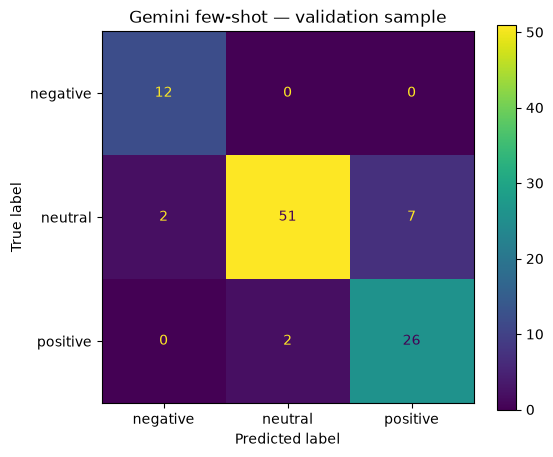

In [ ]:
#confusion matrix
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

labels = ["negative", "neutral", "positive"]

cm_few = confusion_matrix(
    y_true_few,
    y_pred_few,
    labels=labels
)

print(cm_few)

fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay(
    confusion_matrix=cm_few,
    display_labels=labels
).plot(ax=ax)

ax.set_title(
    "Gemini few-shot — validation sample"
)

plt.show()

In [ ]:
#Comparison with zero-shot
comparison = pd.DataFrame({
    "Setup": [
        "Zero-shot",
        "Few-shot"
    ],
    "Accuracy": [
        0.86,
        few_accuracy
    ],
    "Macro-F1": [
        0.8775757575757576,
        few_macro_f1
    ]
})

comparison

,Setup,Accuracy,Macro-F1
0,Zero-shot,0.86,0.877576
1,Few-shot,0.89,0.892730
